# Predicción de la pobreza por ingresos (versión 2: optimización bayesiana) en hogares mexicanos (ENIGH 2016–2020) con aprendizaje automático

**Objetivo.** Clasificar si un hogar se encuentra por debajo de la línea de pobreza por ingresos (`plp = 1`) a partir de sus características sociodemográficas, de seguridad alimentaria, de vivienda y de equipamiento, **sin usar el ingreso** como predictor.

**Modelos comparados (7):**
1. Red neuronal totalmente conectada (FCNN) 128‑64‑32‑16‑1 (Keras/TensorFlow)
2. Random Forest
3. Regresión logística
4. Perceptrón multicapa (MLP, scikit‑learn)
5. Perceptrón simple (clásico) y perceptrón promediado (*averaged perceptron*)
6. XGBoost
7. Gradient Boosting (implementación por histogramas de scikit‑learn, `HistGradientBoostingClassifier`)

**Mejoras respecto al flujo original**

| # | Flujo original | Flujo mejorado | Motivo |
|---|---|---|---|
| 1 | Se eliminaban 5 838 filas con nulos | Imputación (mediana / moda) ajustada solo con entrenamiento + indicador de nulo | Conservar información y evitar sesgo de selección |
| 2 | Sin escalado | `StandardScaler` para variables numéricas | Recomendado para modelos entrenados por gradiente (redes neuronales, regresión logística) |
| 3 | División aleatoria 80/20 sin estratificar | División estratificada 80/20 + 10 % de validación interna | Mantener la proporción de clases y permitir *early stopping* |
| 4 | Hiperparámetros por defecto | Optimización bayesiana TPE (Optuna) + poda Hyperband + *early stopping* | Exploración más eficiente del espacio de hiperparámetros |
| 5 | Variables originales | Ingeniería de características (hacinamiento, dependencia, índice de bienes, etc.) | Capturar relaciones de dominio |
| 6 | Escolaridad en *one‑hot* | Escolaridad como variable ordinal | Respeta el orden natural de los niveles educativos |
| 7 | Accuracy, precisión, recall, F1 | + ROC‑AUC, MCC, IC 95 % por *bootstrap* y prueba de McNemar | Evaluación más robusta y comparación estadística |
| 8 | FCNN 128‑64‑32 sin regularización | FCNN 128‑64‑32‑16‑1 con BatchNorm, Dropout, L2, *early stopping* | Mejor generalización |
| 9 | Perceptrón clásico | + Perceptrón promediado | El perceptrón clásico es inestable con datos no separables linealmente |
| 10 | Modelos aislados | + Ensamble ponderado con pesos optimizados | Combina las fortalezas de varios modelos |
| 11 | Umbral fijo 0.5 | + Umbral calibrado en validación | Ajusta el punto de corte a la distribución de probabilidades de cada modelo |

**Cómo reproducir en Google Colab:** ejecute las celdas en orden (`Entorno de ejecución → Ejecutar todas`). Ajuste únicamente la variable `RUTA_DATOS` de la sección 2 y descomente la instalación de Optuna en la sección 10. El tiempo total aproximado es de 60–90 min en un entorno de CPU estándar; puede reducirlo con `MODO_RAPIDO = True`.

## Índice
1. Configuración del entorno
2. Carga de datos
3. Integración y validación de los datos
4. Análisis exploratorio
5. Definición del problema y selección de variables
6. Ingeniería de características
7. División de los datos
8. Preprocesamiento
9. Funciones de evaluación
10. Optimización bayesiana de hiperparámetros (Optuna)
11. Entrenamiento final, ensamble y calibración del umbral
12. Comparación de modelos y pruebas estadísticas
13. Visualizaciones
14. Estudio de ablación (efecto de cada mejora)
15. Interpretabilidad: importancia por permutación
16. Exportación de resultados
17. Conclusiones

## 1. Configuración del entorno

In [1]:
# En Colab, scikit-learn, XGBoost y TensorFlow ya vienen instalados.
# Si alguna librería faltara, descomente la siguiente línea:
# !pip install -q xgboost

In [2]:
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix,
                             classification_report, roc_curve)
from scipy.stats import chi2, loguniform, uniform, randint
import xgboost as xgb
import sklearn

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

# ---------------- Reproducibilidad ----------------
SEMILLA = 42
np.random.seed(SEMILLA)
keras.utils.set_random_seed(SEMILLA)

# ---------------- Parámetros globales ----------------
MODO_RAPIDO = False          # True: búsquedas más pequeñas (útil para pruebas)
N_MUESTRA_BUSQUEDA = 30_000 if MODO_RAPIDO else 60_000   # tamaño de la submuestra para tuning
CARPETA_SALIDA = "resultados_pobreza_v2"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("scikit-learn:", sklearn.__version__, "| XGBoost:", xgb.__version__,
      "| TensorFlow:", tf.__version__, "| pandas:", pd.__version__)

I0000 00:00:1793994352.513632    3244 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793994355.454736    3244 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


scikit-learn: 1.9.1 | XGBoost: 3.4.1 | TensorFlow: 2.21.0 | pandas: 3.0.6


## 2. Carga de datos
Los archivos `base2016.xlsx`, `base2018.xlsx` y `base2020.xlsx` provienen de la Encuesta Nacional de Ingresos y Gastos de los Hogares (ENIGH) del INEGI. Cada registro corresponde a un **hogar**.

In [3]:
# Montar Google Drive solo si se ejecuta en Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RUTA_DATOS = "/content/drive/Shareddrives/PLANEACIÓN DE MATERIAS/MCI_I2026_MINERÍA DE DATOS/DATASETS/"
except ImportError:
    # Ejecución local: ajuste la ruta o defina la variable de entorno RUTA_DATOS
    RUTA_DATOS = os.environ.get("RUTA_DATOS", "./")

def leer_datos(ruta):
    # La primera columna del Excel es un índice sin significado
    return pd.read_excel(ruta, sheet_name="Sheet1", index_col=0)

ANIOS = [2016, 2018, 2020]
bases = {a: leer_datos(os.path.join(RUTA_DATOS, f"base{a}.xlsx")) for a in ANIOS}
for a, d in bases.items():
    print(f"ENIGH {a}: {d.shape[0]:,} hogares, {d.shape[1]} columnas")

ENIGH 2016: 70,311 hogares, 34 columnas
ENIGH 2018: 74,647 hogares, 34 columnas
ENIGH 2020: 89,006 hogares, 34 columnas


## 3. Integración y validación de los datos

In [4]:
# Verificar que las tres bases tengan exactamente las mismas columnas
columnas_ref = list(bases[2016].columns)
assert all(list(d.columns) == columnas_ref for d in bases.values()), "Las bases no tienen las mismas columnas"

for a, d in bases.items():
    d["anio"] = a
df = pd.concat(bases.values(), axis=0, ignore_index=True)
print("Registros totales:", f"{len(df):,}")
print("Hogares duplicados (sin considerar folios):",
      df.drop(columns=["folioviv", "foliohog"]).duplicated().sum())
df.head()

Registros totales: 233,964


Hogares duplicados (sin considerar folios): 0


,folioviv,foliohog,plp,plp_e,ictpc,entidad,rur_urb,mujer_jefe_hog,escolaridad_educacion_jh,tot_trab,recibe_ayuda_apoyo_gub,edad_jefe,tot_integ,prog_soc_porcent,escala_elcsa,acc_alim_preocupo,acc_alim_sin_alim,acc_alim_no_alim_sal,acc_alim_poca_var,acc_alim_no_come,acc_alim_come_menos,acc_alim_hambre,acc_alim_no_come_dia,auto_camioneta_van,conex_inte,compu,lavad,equip_tel_fijo,refri,hindig,discap,tot_integ_0_17,num_cuarto,bano_comp,anio
0,100003801,1,0,0,17191.509772,1,0,0,10,2,0,33,2,0.0,2,1,0,1,1,0,0,0,1,1,1,1,1.0,0,1.0,0,0,0,5,1.0,2016
1,100003802,1,0,0,24891.201922,1,0,0,10,2,0,29,2,0.0,0,0,0,0,0,0,0,0,0,1,0,0,1.0,0,1.0,0,0,0,5,1.0,2016
2,100003803,1,0,0,5713.706100,1,0,0,10,1,0,47,6,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,1,1.0,0,0,4,8,2.0,2016
3,100003804,1,0,0,6630.419310,1,0,1,11,2,0,29,3,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,0,1.0,0,0,0,5,2.0,2016
4,100003805,1,0,0,7227.184554,1,0,0,10,1,0,55,2,0.0,0,0,0,0,0,0,0,0,0,1,1,1,1.0,1,1.0,0,0,0,6,2.0,2016


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 233964 entries, 0 to 233963
Data columns (total 35 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   folioviv                  233964 non-null  int64  
 1   foliohog                  233964 non-null  int64  
 2   plp                       233964 non-null  int64  
 3   plp_e                     233964 non-null  int64  
 4   ictpc                     233964 non-null  float64
 5   entidad                   233964 non-null  int64  
 6   rur_urb                   233964 non-null  int64  
 7   mujer_jefe_hog            233964 non-null  int64  
 8   escolaridad_educacion_jh  233964 non-null  int64  
 9   tot_trab                  233964 non-null  int64  
 10  recibe_ayuda_apoyo_gub    233964 non-null  int64  
 11  edad_jefe                 233964 non-null  int64  
 12  tot_integ                 233964 non-null  int64  
 13  prog_soc_porcent          233937 non-null  float64
 14 

## 4. Análisis exploratorio

In [6]:
# 4.1 Valores faltantes
nulos = df.isna().sum()
display(nulos[nulos > 0].to_frame("n_nulos").assign(porcentaje=lambda t: 100 * t.n_nulos / len(df)))

,n_nulos,porcentaje
prog_soc_porcent,27,0.011540
lavad,1,0.000427
refri,1,0.000427
bano_comp,5810,2.483288


In [7]:
# 4.2 Balance de clases de las posibles variables objetivo
balance = pd.DataFrame({
    "No pobre (0)": [df.plp.eq(0).sum(), df.plp_e.eq(0).sum()],
    "Pobre (1)":    [df.plp.eq(1).sum(), df.plp_e.eq(1).sum()]},
    index=["plp (pobreza por ingresos)", "plp_e (pobreza extrema por ingresos)"])
balance["% clase 1"] = 100 * balance["Pobre (1)"] / balance.sum(axis=1)
display(balance)

# Prevalencia de pobreza por año y tipo de localidad (rur_urb = 1: rural)
display((100 * df.groupby(["anio", "rur_urb"]).plp.mean()).unstack().round(2)
        .rename(columns={0: "% pobres urbano", 1: "% pobres rural"}))

,No pobre (0),Pobre (1),% clase 1
plp (pobreza por ingresos),132594,101370,43.327179
plp_e (pobreza extrema por ingresos),204500,29464,12.593390


rur_urb,% pobres urbano,% pobres rural
anio,,
2016,41.10,47.14
2018,40.28,46.57
2020,43.01,45.34


In [8]:
# 4.3 Verificación de la variable escala_elcsa: es una función exacta de las 8 preguntas de acceso a la alimentación
ALIM = ["acc_alim_preocupo", "acc_alim_sin_alim", "acc_alim_no_alim_sal", "acc_alim_poca_var",
        "acc_alim_no_come", "acc_alim_come_menos", "acc_alim_hambre", "acc_alim_no_come_dia"]
suma = df[ALIM].sum(axis=1)
elcsa_calc = np.select([suma == 0, suma <= 3, suma <= 6], [0, 1, 2], 3)
print("Coincidencia escala_elcsa calculada vs. registrada:", f"{(elcsa_calc == df.escala_elcsa).mean():.2%}")

Coincidencia escala_elcsa calculada vs. registrada: 100.00%


In [9]:
# 4.4 Verificación de fuga de información: plp se obtiene comparando ictpc con la línea de pobreza
# del año y tipo de localidad. Si ictpc se usara como predictor, el problema sería trivial.
umbrales = df.groupby(["anio", "rur_urb", "plp"]).ictpc.agg(["min", "max"]).round(1)
display(umbrales)

min        max
anio rur_urb plp                   
2016 0       0    2045.3  1918799.8
             1       0.0     2903.7
     1       0    2030.2   301092.2
             1       0.0     2030.0
2018 0       0    2441.1   278164.8
             1       0.0     3325.3
     1       0    2316.6   771619.8
             1       0.0     2316.0
2020 0       0    2525.5  2182944.0
             1       0.0     3559.7
     1       0    2520.6   780927.3
             1       0.0     2520.1

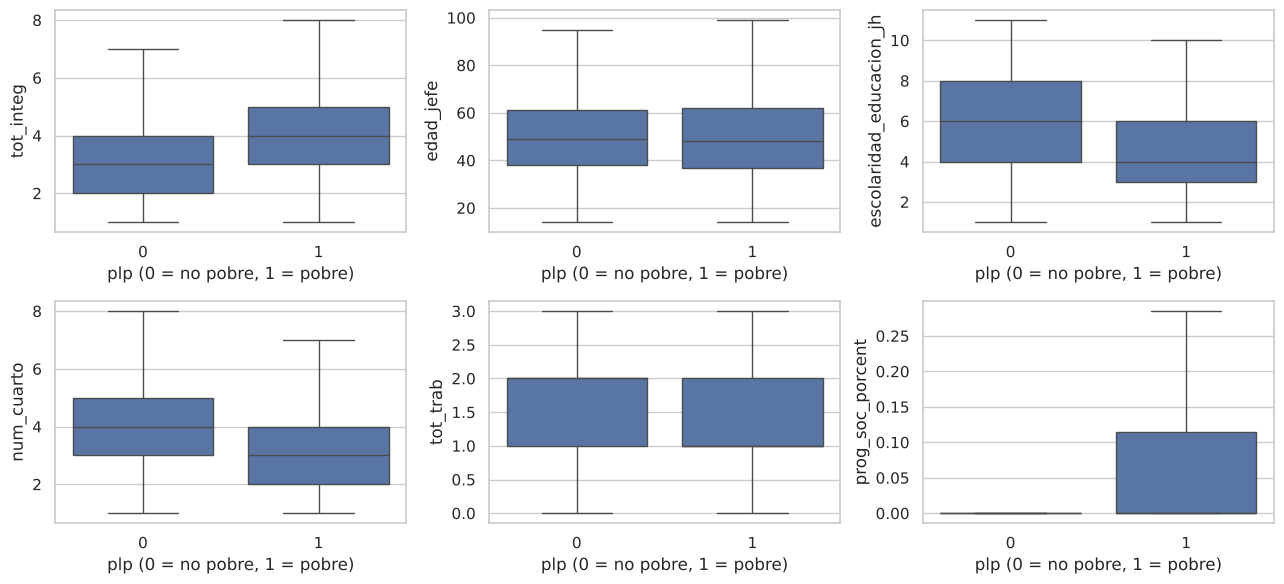

In [10]:
# 4.5 Distribución de algunas variables numéricas por clase
num_vis = ["tot_integ", "edad_jefe", "escolaridad_educacion_jh", "num_cuarto", "tot_trab", "prog_soc_porcent"]
fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for a_, c in zip(ax.ravel(), num_vis):
    sns.boxplot(data=df, x="plp", y=c, ax=a_, showfliers=False)
    a_.set_xlabel("plp (0 = no pobre, 1 = pobre)")
plt.tight_layout(); plt.show()

## 5. Definición del problema y selección de variables
* **Variable objetivo:** `plp` (1 = hogar con ingreso per cápita por debajo de la línea de pobreza por ingresos). Presenta un balance razonable (≈43 % de clase 1).
* `plp_e` no se usa como objetivo en este estudio: su clase positiva representa solo ≈12.6 % de los hogares, por lo que requeriría un tratamiento específico de desbalance; queda como trabajo futuro.
* **Variables excluidas:**
  * `folioviv`, `foliohog`: identificadores sin valor predictivo.
  * `ictpc`, `plp_e`: **fuga de información** (la etiqueta se deriva directamente del ingreso).
  * `escala_elcsa`: redundante (combinación exacta de las 8 variables `acc_alim_*`, verificado en 4.3).

In [11]:
OBJETIVO = "plp"
EXCLUIR = ["folioviv", "foliohog", "ictpc", "plp_e", "escala_elcsa"]
y = df[OBJETIVO].astype(int).values
X_raw = df.drop(columns=EXCLUIR + [OBJETIVO])
print("Predictores originales:", X_raw.shape[1])
print(list(X_raw.columns))

Predictores originales: 29
['entidad', 'rur_urb', 'mujer_jefe_hog', 'escolaridad_educacion_jh', 'tot_trab', 'recibe_ayuda_apoyo_gub', 'edad_jefe', 'tot_integ', 'prog_soc_porcent', 'acc_alim_preocupo', 'acc_alim_sin_alim', 'acc_alim_no_alim_sal', 'acc_alim_poca_var', 'acc_alim_no_come', 'acc_alim_come_menos', 'acc_alim_hambre', 'acc_alim_no_come_dia', 'auto_camioneta_van', 'conex_inte', 'compu', 'lavad', 'equip_tel_fijo', 'refri', 'hindig', 'discap', 'tot_integ_0_17', 'num_cuarto', 'bano_comp', 'anio']


## 6. Ingeniería de características
Se crean variables derivadas, calculadas **fila por fila** (no usan información de otros hogares, por lo que no generan fuga):

| Variable | Definición | Interpretación |
|---|---|---|
| `tasa_dependencia` | `tot_integ_0_17 / tot_integ` | Proporción de menores en el hogar |
| `trab_por_integ` | `tot_trab / tot_integ` | Integrantes ocupados por persona |
| `hacinamiento` | `tot_integ / num_cuarto` | Personas por cuarto |
| `integ_por_bano` | `tot_integ / (bano_comp + 1)` | Presión sobre servicios sanitarios |
| `inseg_alim_suma` | suma de las 8 `acc_alim_*` | Intensidad de inseguridad alimentaria |
| `indice_bienes` | suma de 6 bienes durables | Índice simple de activos del hogar |
| `sin_trabajador` | `tot_trab == 0` | Hogar sin ingreso laboral |
| `bano_comp_nulo` | `bano_comp` faltante | Indicador de dato faltante |

In [12]:
BIENES = ["auto_camioneta_van", "conex_inte", "compu", "lavad", "equip_tel_fijo", "refri"]

def ingenieria_caracteristicas(X):
    X = X.copy()
    X["bano_comp_nulo"]   = X["bano_comp"].isna().astype(int)
    X["tasa_dependencia"] = X["tot_integ_0_17"] / X["tot_integ"]
    X["trab_por_integ"]   = X["tot_trab"] / X["tot_integ"]
    X["hacinamiento"]     = X["tot_integ"] / X["num_cuarto"].clip(lower=1)
    X["integ_por_bano"]   = X["tot_integ"] / (X["bano_comp"].fillna(0) + 1)
    X["inseg_alim_suma"]  = X[ALIM].sum(axis=1)
    X["indice_bienes"]    = X[BIENES].sum(axis=1, min_count=1)
    X["sin_trabajador"]   = (X["tot_trab"] == 0).astype(int)
    return X

X = ingenieria_caracteristicas(X_raw)
print("Predictores tras la ingeniería de características:", X.shape[1])

Predictores tras la ingeniería de características: 37


## 7. División de los datos
* 80 % entrenamiento / 20 % prueba, **estratificada** por `plp`.
* Del entrenamiento se reserva un 10 % estratificado como **validación** para el *early stopping* de XGBoost y de la FCNN.
* El conjunto de prueba **no se utiliza** en ninguna decisión de entrenamiento ni de ajuste.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEMILLA)

resumen_div = pd.DataFrame({
    "n": [len(X_train), len(X_tr), len(X_val), len(X_test)],
    "% pobres": [100*y_train.mean(), 100*y_tr.mean(), 100*y_val.mean(), 100*y_test.mean()]},
    index=["Entrenamiento completo", "  - Sub-entrenamiento", "  - Validación", "Prueba"]).round(2)
display(resumen_div)

,n,% pobres
Entrenamiento completo,187171,43.33
- Sub-entrenamiento,168453,43.33
- Validación,18718,43.33
Prueba,46793,43.33


## 8. Preprocesamiento
`ColumnTransformer` ajustado **solo con datos de entrenamiento**:
* **Numéricas** (incluye escolaridad ordinal y variables derivadas): imputación por mediana + `StandardScaler`.
* **Binarias:** imputación por moda (sin escalar).
* **Categóricas nominales** (`entidad`, `anio`): `OneHotEncoder`.

In [14]:
CAT = ["entidad", "anio"]
BIN = ["rur_urb", "mujer_jefe_hog", "recibe_ayuda_apoyo_gub"] + ALIM + BIENES + \
      ["hindig", "discap", "bano_comp_nulo", "sin_trabajador"]
NUM = [c for c in X.columns if c not in CAT + BIN]
print("Numéricas:", NUM, "\nBinarias:", len(BIN), "| Categóricas:", CAT)

def crear_preprocesador(escalar=True):
    pasos_num = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("esc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), NUM),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

pre = crear_preprocesador().fit(X_train)          # para modelos ajustados con todo el entrenamiento
pre_tr = crear_preprocesador().fit(X_tr)          # para modelos con validación (XGBoost, FCNN)

Xt_train, Xt_test = pre.transform(X_train), pre.transform(X_test)
Xs_tr, Xs_val, Xs_test = pre_tr.transform(X_tr), pre_tr.transform(X_val), pre_tr.transform(X_test)
nombres_finales = pre.get_feature_names_out()
print("Dimensión de la matriz final:", Xt_train.shape)

Numéricas: ['escolaridad_educacion_jh', 'tot_trab', 'edad_jefe', 'tot_integ', 'prog_soc_porcent', 'tot_integ_0_17', 'num_cuarto', 'bano_comp', 'tasa_dependencia', 'trab_por_integ', 'hacinamiento', 'integ_por_bano', 'inseg_alim_suma', 'indice_bienes'] 
Binarias: 21 | Categóricas: ['entidad', 'anio']


Dimensión de la matriz final: (187171, 70)


## 9. Funciones de evaluación

In [15]:
resultados, predicciones, tiempos = [], {}, {}

def evaluar(nombre, y_true, puntaje, pred):
    # puntaje: probabilidad o función de decisión (para ROC-AUC); pred: clase predicha
    rep = classification_report(y_true, pred, digits=4, output_dict=True)
    fila = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": rep["weighted avg"]["precision"],
        "Recall": rep["weighted avg"]["recall"],
        "F1-score": rep["weighted avg"]["f1-score"],
        "Precision (pobre)": rep["1"]["precision"],
        "Recall (pobre)": rep["1"]["recall"],
        "F1 (pobre)": rep["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_true, puntaje),
        "MCC": matthews_corrcoef(y_true, pred)}
    print(f"\n===== {nombre} =====")
    print(classification_report(y_true, pred, digits=4, target_names=["No pobre", "Pobre"]))
    print(f"ROC-AUC: {fila['ROC-AUC']:.4f} | MCC: {fila['MCC']:.4f}")
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(4, 3.2))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["No pobre", "Pobre"], yticklabels=["No pobre", "Pobre"])
    plt.title(f"Matriz de confusión – {nombre}"); plt.xlabel("Predicción"); plt.ylabel("Real")
    plt.tight_layout(); plt.show()
    return fila

def registrar(nombre, puntaje, pred, t):
    predicciones[nombre] = {"puntaje": np.asarray(puntaje), "pred": np.asarray(pred)}
    tiempos[nombre] = t
    resultados.append(evaluar(nombre, y_test, puntaje, pred) | {"Tiempo (s)": t})

## 10. Optimización bayesiana de hiperparámetros (Optuna)

En la versión 1 se usó **búsqueda aleatoria** (`RandomizedSearchCV`). Aquí se sustituye por técnicas más avanzadas:

| Técnica | Qué hace | Dónde se usa |
|---|---|---|
| **TPE multivariado** (*Tree-structured Parzen Estimator*) | Modela qué regiones del espacio producen buenos resultados y propone nuevas configuraciones ahí, considerando interacciones entre hiperparámetros | Todos los modelos |
| **Poda Hyperband** | Detiene tempranamente las configuraciones poco prometedoras a partir de sus resultados parciales (épocas) | FCNN |
| **Early stopping** dentro de cada prueba | Determina automáticamente el número de árboles / épocas | XGBoost, Gradient Boosting, MLP, FCNN |
| **Optimización de pesos del ensamble** | Busca la combinación ponderada de probabilidades que mejor generaliza | Ensamble final |
| **Calibración del umbral de decisión** | Elige el umbral que maximiza la exactitud en validación (en lugar de 0.5 fijo) | Todos los modelos probabilísticos |

**Protocolo (sin fuga de información):** cada configuración se entrena con el *sub-entrenamiento* (168 453 hogares) y se evalúa con el conjunto de **validación** (18 718 hogares). El conjunto de **prueba** no se usa en ninguna decisión; solo se evalúa una vez al final. Los modelos finales se entrenan con el sub-entrenamiento para que la validación siga siendo independiente al ajustar los pesos del ensamble y el umbral.

**Persistencia:** los estudios se guardan en una base SQLite. Si Colab se desconecta, al volver a ejecutar las celdas la optimización **continúa** donde quedó. Para reiniciar desde cero, borre el archivo `optuna_pobreza.db`.

In [16]:
# En Colab: instalar Optuna (no viene preinstalado)
# !pip install -q optuna
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import HyperbandPruner
optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Optuna:", optuna.__version__)

ALMACEN = f"sqlite:///{os.path.join(CARPETA_SALIDA, 'optuna_pobreza.db')}"
N_PRUEBAS = {"Regresión logística": 20, "Perceptrón": 25, "Perceptrón promediado": 20,
             "Perceptrón multicapa": 12, "Random Forest": 15, "XGBoost": 30,
             "Gradient Boosting": 25, "FCNN": 12}
if MODO_RAPIDO:
    N_PRUEBAS = {k: max(4, v // 4) for k, v in N_PRUEBAS.items()}

def optimizar(nombre, objetivo, pruner=None):
    # Crea (o reanuda) un estudio TPE y ejecuta solo las pruebas que falten.
    estudio = optuna.create_study(
        study_name=nombre, storage=ALMACEN, load_if_exists=True, direction="maximize",
        sampler=TPESampler(seed=SEMILLA, multivariate=True, n_startup_trials=8),
        pruner=pruner or optuna.pruners.NopPruner())
    hechas = len([t for t in estudio.trials if t.state in (optuna.trial.TrialState.COMPLETE,
                                                          optuna.trial.TrialState.PRUNED)])
    faltan = max(0, N_PRUEBAS[nombre] - hechas)
    t0 = time.time()
    if faltan:
        estudio.optimize(objetivo, n_trials=faltan, gc_after_trial=True)
    podadas = sum(t.state == optuna.trial.TrialState.PRUNED for t in estudio.trials)
    print(f"{nombre}: mejor exactitud en validación = {estudio.best_value:.4f} | "
          f"pruebas = {len(estudio.trials)} (podadas: {podadas}) | {time.time()-t0:.0f} s")
    print("  Mejores hiperparámetros:", estudio.best_params)
    return estudio

acc_val = lambda modelo: accuracy_score(y_val, modelo.predict(Xs_val))
estudios = {}

Optuna: 5.0.0


### 10.1 Regresión logística

In [17]:
def obj_lr(trial):
    m = LogisticRegression(C=trial.suggest_float("C", 1e-4, 1e2, log=True),
                           class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
                           max_iter=3000)
    return acc_val(m.fit(Xs_tr, y_tr))
estudios["Regresión logística"] = optimizar("Regresión logística", obj_lr)

Regresión logística: mejor exactitud en validación = 0.7625 | pruebas = 20 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'C': 0.013443984756825128, 'class_weight': None}


### 10.2 Perceptrón simple y perceptrón promediado

In [18]:
def obj_per(trial):
    m = Perceptron(penalty=trial.suggest_categorical("penalty", [None, "l2", "l1", "elasticnet"]),
                   alpha=trial.suggest_float("alpha", 1e-7, 1e-2, log=True),
                   eta0=trial.suggest_float("eta0", 1e-3, 1.0, log=True),
                   class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
                   early_stopping=trial.suggest_categorical("early_stopping", [True, False]),
                   max_iter=200, random_state=SEMILLA)
    return acc_val(m.fit(Xs_tr, y_tr))
estudios["Perceptrón"] = optimizar("Perceptrón", obj_per)

def obj_per_avg(trial):
    m = SGDClassifier(loss="perceptron", average=True, max_iter=50, tol=1e-4, random_state=SEMILLA,
                      penalty=trial.suggest_categorical("penalty", ["l2", "l1", "elasticnet"]),
                      alpha=trial.suggest_float("alpha", 1e-7, 1e-2, log=True),
                      class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]))
    return acc_val(m.fit(Xs_tr, y_tr))
estudios["Perceptrón promediado"] = optimizar("Perceptrón promediado", obj_per_avg)

Perceptrón: mejor exactitud en validación = 0.7302 | pruebas = 25 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'penalty': None, 'alpha': 9.761125443110459e-05, 'eta0': 0.5829384542994738, 'class_weight': 'balanced', 'early_stopping': False}
Perceptrón promediado: mejor exactitud en validación = 0.7630 | pruebas = 20 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'penalty': 'l2', 'alpha': 1.1418029792576083e-07, 'class_weight': None}


### 10.3 Perceptrón multicapa (MLP)

In [19]:
ARQ_MLP = {"128": (128,), "256": (256,), "128-64": (128, 64), "256-128": (256, 128), "128-64-32": (128, 64, 32)}
def obj_mlp(trial):
    m = MLPClassifier(hidden_layer_sizes=ARQ_MLP[trial.suggest_categorical("capas", list(ARQ_MLP))],
                      activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
                      alpha=trial.suggest_float("alpha", 1e-6, 1e-2, log=True),
                      learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 3e-3, log=True),
                      batch_size=trial.suggest_categorical("batch_size", [256, 512, 1024]),
                      early_stopping=True, n_iter_no_change=10, max_iter=200, random_state=SEMILLA)
    return acc_val(m.fit(Xs_tr, y_tr))
estudios["Perceptrón multicapa"] = optimizar("Perceptrón multicapa", obj_mlp)

Perceptrón multicapa: mejor exactitud en validación = 0.7821 | pruebas = 12 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'capas': '256', 'activation': 'tanh', 'alpha': 8.940120878901744e-05, 'learning_rate_init': 0.0002130063372301053, 'batch_size': 512}


### 10.4 Random Forest
Para acotar el costo, cada prueba usa 150 árboles y una submuestra estratificada de 60 000 hogares del sub-entrenamiento; el modelo final se entrena con 400 árboles y todo el sub-entrenamiento.

In [20]:
idx_rf, _ = train_test_split(np.arange(len(y_tr)), train_size=N_MUESTRA_BUSQUEDA, stratify=y_tr, random_state=SEMILLA)
def obj_rf(trial):
    prof = trial.suggest_categorical("max_depth", [0, 12, 16, 20, 25, 30, 40])
    m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=SEMILLA,
                               max_depth=None if prof == 0 else prof,
                               min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 40, log=True),
                               max_features=trial.suggest_float("max_features", 0.15, 0.8),
                               max_samples=trial.suggest_float("max_samples", 0.5, 1.0),
                               criterion=trial.suggest_categorical("criterion", ["gini", "entropy"]))
    return acc_val(m.fit(Xs_tr[idx_rf], y_tr[idx_rf]))
estudios["Random Forest"] = optimizar("Random Forest", obj_rf)

Random Forest: mejor exactitud en validación = 0.7711 | pruebas = 15 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'max_depth': 0, 'min_samples_leaf': 1, 'max_features': 0.4591831618474195, 'max_samples': 0.5405231550727798, 'criterion': 'gini'}


### 10.5 XGBoost (con *early stopping* en cada prueba)

In [21]:
def params_xgb(trial):
    return {"learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 12),
            "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
            "colsample_bynode": trial.suggest_float("colsample_bynode", 0.5, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 20, log=True),
            "gamma": trial.suggest_float("gamma", 0, 5)}
def obj_xgb(trial):
    m = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="logloss",
                          early_stopping_rounds=50, random_state=SEMILLA, n_jobs=-1, **params_xgb(trial))
    m.fit(Xs_tr, y_tr, eval_set=[(Xs_val, y_val)], verbose=False)
    trial.set_user_attr("n_arboles", int(m.best_iteration) + 1)
    return acc_val(m)
estudios["XGBoost"] = optimizar("XGBoost", obj_xgb)

XGBoost: mejor exactitud en validación = 0.7845 | pruebas = 31 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'learning_rate': 0.041040345896217585, 'max_depth': 5, 'min_child_weight': 8.356499023325524, 'subsample': 0.5704621124873813, 'colsample_bytree': 0.8813181884524238, 'colsample_bynode': 0.5372753218398854, 'reg_alpha': 8.862326508576253, 'reg_lambda': 3.5416296712651336, 'gamma': 0.993578407670862}


### 10.6 Gradient Boosting (HistGradientBoostingClassifier)

In [22]:
def obj_gb(trial):
    prof = trial.suggest_categorical("max_depth", [0, 6, 8, 10, 12, 16])
    m = HistGradientBoostingClassifier(
        max_iter=2000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30, random_state=SEMILLA,
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 255, log=True),
        max_depth=None if prof == 0 else prof,
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 300, log=True),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        max_features=trial.suggest_float("max_features", 0.3, 1.0))
    return acc_val(m.fit(Xs_tr, y_tr))
estudios["Gradient Boosting"] = optimizar("Gradient Boosting", obj_gb)

Gradient Boosting: mejor exactitud en validación = 0.7853 | pruebas = 25 (podadas: 0) | 0 s
  Mejores hiperparámetros: {'max_depth': 6, 'learning_rate': 0.10020860250997343, 'max_leaf_nodes': 37, 'min_samples_leaf': 77, 'l2_regularization': 7.39151577655969, 'max_features': 0.3192228966861973}


### 10.7 FCNN 128‑64‑32‑16‑1 con poda Hyperband
La **arquitectura se mantiene fija** (128‑64‑32‑16‑1). Se optimizan la regularización (*dropout* por capa, L2), el uso de *Batch Normalization*, la función de activación, el optimizador (Adam o AdamW con *weight decay*), la tasa de aprendizaje y el tamaño de lote. Después de cada época se reporta la exactitud de validación a Optuna; la poda **Hyperband** detiene las configuraciones que van peor que las demás en el mismo número de épocas.

In [23]:
def construir_fcnn_opt(n_entradas, hp):
    entrada = keras.Input(shape=(n_entradas,))
    x = entrada
    for i, u in enumerate((128, 64, 32, 16)):
        x = layers.Dense(u, kernel_regularizer=regularizers.l2(hp["l2"]))(x)
        if hp["batchnorm"]:
            x = layers.BatchNormalization()(x)
        x = layers.Activation(hp["activacion"])(x)
        x = layers.Dropout(hp[f"dropout_{i+1}"])(x)
    salida = layers.Dense(1, activation="sigmoid")(x)
    modelo = keras.Model(entrada, salida, name="FCNN_128_64_32_16_1")
    if hp["optimizador"] == "adamw":
        opt = keras.optimizers.AdamW(learning_rate=hp["lr"], weight_decay=hp["weight_decay"])
    else:
        opt = keras.optimizers.Adam(learning_rate=hp["lr"])
    modelo.compile(optimizer=opt, loss="binary_crossentropy",
                   metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return modelo

def hp_fcnn(trial):
    hp = {f"dropout_{i}": trial.suggest_float(f"dropout_{i}", 0.0, 0.5) for i in range(1, 5)}
    hp.update(l2=trial.suggest_float("l2", 1e-7, 1e-3, log=True),
              batchnorm=trial.suggest_categorical("batchnorm", [True, False]),
              activacion=trial.suggest_categorical("activacion", ["relu", "gelu", "swish"]),
              optimizador=trial.suggest_categorical("optimizador", ["adam", "adamw"]),
              lr=trial.suggest_float("lr", 3e-4, 5e-3, log=True),
              batch=trial.suggest_categorical("batch", [512, 1024, 2048]))
    hp["weight_decay"] = trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True) if hp["optimizador"] == "adamw" else 0.0
    return hp

class ReportarOptuna(keras.callbacks.Callback):
    # Reporta la exactitud de validación por época y aplica la poda Hyperband
    def __init__(self, trial): super().__init__(); self.trial = trial
    def on_epoch_end(self, epoch, logs=None):
        self.trial.report(logs["val_accuracy"], step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()

EPOCAS_MAX = 60
def obj_fcnn(trial):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEMILLA)
    hp = hp_fcnn(trial)
    m = construir_fcnn_opt(Xs_tr.shape[1], hp)
    m.fit(Xs_tr, y_tr, validation_data=(Xs_val, y_val), epochs=EPOCAS_MAX, batch_size=hp["batch"], verbose=0,
          callbacks=[ReportarOptuna(trial),
                     keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=8, restore_best_weights=True),
                     keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)])
    return float(accuracy_score(y_val, (m.predict(Xs_val, batch_size=4096, verbose=0).ravel() >= 0.5)))

estudios["FCNN"] = optimizar("FCNN", obj_fcnn,
                             pruner=HyperbandPruner(min_resource=5, max_resource=EPOCAS_MAX, reduction_factor=3))

FCNN: mejor exactitud en validación = 0.7833 | pruebas = 12 (podadas: 8) | 0 s
  Mejores hiperparámetros: {'dropout_1': 0.4828160165372797, 'dropout_2': 0.40419867405823057, 'dropout_3': 0.15230688458668534, 'dropout_4': 0.048836057003191935, 'l2': 5.456725485601477e-05, 'batchnorm': True, 'activacion': 'swish', 'optimizador': 'adamw', 'lr': 0.0007210826453049432, 'batch': 1024, 'weight_decay': 0.00755681014127443}


### 10.8 Historial de optimización y resumen de hiperparámetros

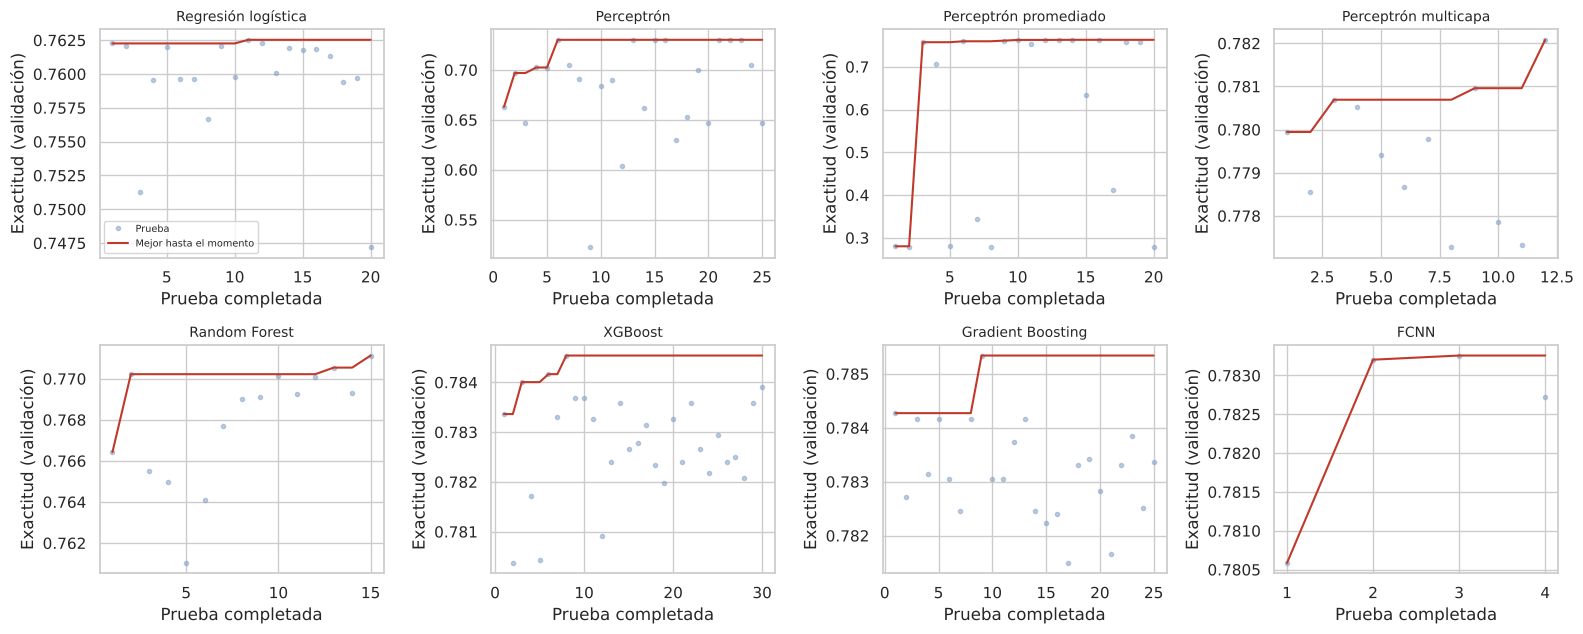

,Modelo,Pruebas,Podadas,Mejor exactitud (validación),Mejores hiperparámetros
0,Regresión logística,20,0,0.762528,"{'C': 0.013443984756825128, 'class_weight': None}"
1,Perceptrón,25,0,0.730153,"{'penalty': None, 'alpha': 9.761125443110459e-05, 'eta0': 0.5829384542994738, 'class_weight': 'balanced', 'early_stopping': False}"
2,Perceptrón promediado,20,0,0.763009,"{'penalty': 'l2', 'alpha': 1.1418029792576083e-07, 'class_weight': None}"
3,Perceptrón multicapa,12,0,0.782081,"{'capas': '256', 'activation': 'tanh', 'alpha': 8.940120878901744e-05, 'learning_rate_init': 0.0002130063372301053, 'batch_size': 512}"
4,Random Forest,15,0,0.771129,"{'max_depth': 0, 'min_samples_leaf': 1, 'max_features': 0.4591831618474195, 'max_samples': 0.5405231550727798, 'criterion': 'gini'}"
5,XGBoost,31,0,0.784539,"{'learning_rate': 0.041040345896217585, 'max_depth': 5, 'min_child_weight': 8.356499023325524, 'subsample': 0.5704621124873813, 'colsample_bytree': 0.8813181884524238, 'colsample_bynode': 0.537275..."
6,Gradient Boosting,25,0,0.785340,"{'max_depth': 6, 'learning_rate': 0.10020860250997343, 'max_leaf_nodes': 37, 'min_samples_leaf': 77, 'l2_regularization': 7.39151577655969, 'max_features': 0.3192228966861973}"
7,FCNN,12,8,0.783257,"{'dropout_1': 0.4828160165372797, 'dropout_2': 0.40419867405823057, 'dropout_3': 0.15230688458668534, 'dropout_4': 0.048836057003191935, 'l2': 5.456725485601477e-05, 'batchnorm': True, 'activacion..."


In [24]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for a_, (nombre, est) in zip(axes.ravel(), estudios.items()):
    vals = [t.value for t in est.trials if t.state == optuna.trial.TrialState.COMPLETE]
    a_.plot(range(1, len(vals) + 1), vals, "o", ms=3, alpha=0.5, color="#7a9cc6", label="Prueba")
    a_.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), "-", color="#c0392b", label="Mejor hasta el momento")
    a_.set_title(nombre, fontsize=10); a_.set_xlabel("Prueba completada"); a_.set_ylabel("Exactitud (validación)")
axes.ravel()[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_historial_optuna.png"), dpi=300); plt.show()

resumen_opt = pd.DataFrame([{"Modelo": n, "Pruebas": len(e.trials),
                             "Podadas": sum(t.state == optuna.trial.TrialState.PRUNED for t in e.trials),
                             "Mejor exactitud (validación)": e.best_value,
                             "Mejores hiperparámetros": e.best_params} for n, e in estudios.items()])
pd.set_option("display.max_colwidth", 200)
display(resumen_opt)
mejores = {n: e.best_params for n, e in estudios.items()}
with open(os.path.join(CARPETA_SALIDA, "mejores_hiperparametros_optuna.json"), "w") as f:
    json.dump(mejores, f, indent=2, default=str)

## 11. Entrenamiento final y evaluación en el conjunto de prueba
Cada modelo se reentrena con sus mejores hiperparámetros sobre el sub-entrenamiento y se evalúa **una sola vez** en el conjunto de prueba. Para cada modelo probabilístico se guardan también las probabilidades de validación, que se usan en el ensamble (11.9) y en la calibración del umbral (11.10).

In [25]:
proba_val, proba_test = {}, {}
def registrar_prob(nombre, modelo_pv, modelo_pt, t):
    proba_val[nombre], proba_test[nombre] = modelo_pv, modelo_pt
    registrar(nombre, modelo_pt, (modelo_pt >= 0.5).astype(int), t)

### 11.1 FCNN 128‑64‑32‑16‑1

Model: "FCNN_128_64_32_16_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 70)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         9,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,929 (81.75 KB)

 Trainable params: 20,449 (79.88 KB)

 Non-trainable params: 480 (1.88 KB)

Épocas entrenadas: 37 | tiempo: 52 s



===== FCNN (128-64-32-16-1) =====
              precision    recall  f1-score   support

    No pobre     0.7811    0.8301    0.8049     26519
       Pobre     0.7579    0.6957    0.7255     20274

    accuracy                         0.7719     46793
   macro avg     0.7695    0.7629    0.7652     46793
weighted avg     0.7710    0.7719    0.7705     46793

ROC-AUC: 0.8531 | MCC: 0.5324


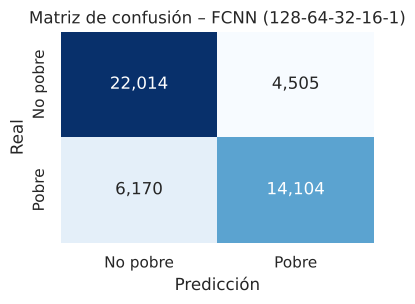

In [26]:
keras.backend.clear_session(); keras.utils.set_random_seed(SEMILLA)
hp_f = dict(mejores["FCNN"]); hp_f.setdefault("weight_decay", 0.0)
fcnn = construir_fcnn_opt(Xs_tr.shape[1], hp_f)
fcnn.summary()
t0 = time.time()
hist = fcnn.fit(Xs_tr, y_tr, validation_data=(Xs_val, y_val), epochs=150, batch_size=hp_f["batch"], verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=12, restore_best_weights=True),
                           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)])
t_f = time.time() - t0
print(f"Épocas entrenadas: {len(hist.history['loss'])} | tiempo: {t_f:.0f} s")
registrar_prob("FCNN (128-64-32-16-1)", fcnn.predict(Xs_val, batch_size=4096, verbose=0).ravel(),
               fcnn.predict(Xs_test, batch_size=4096, verbose=0).ravel(), t_f)

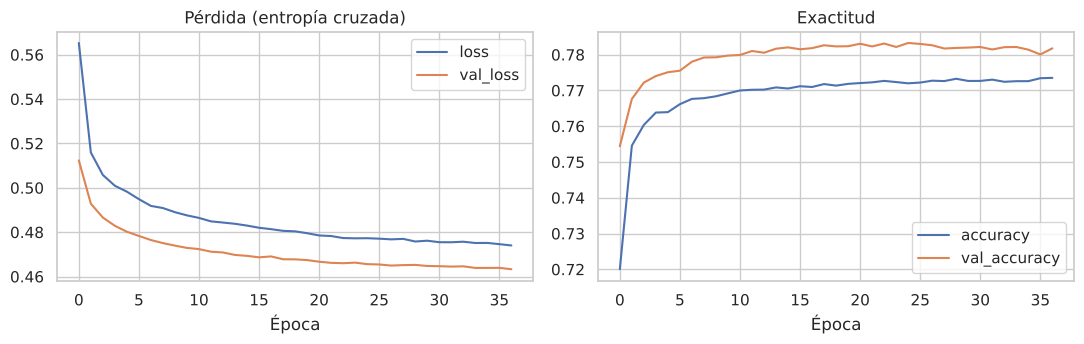

In [27]:
h = pd.DataFrame(hist.history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Pérdida (entropía cruzada)")
h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Exactitud")
for a_ in ax: a_.set_xlabel("Época")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_curvas_fcnn.png"), dpi=300); plt.show()

### 11.2 Random Forest


===== Random Forest =====
              precision    recall  f1-score   support

    No pobre     0.7803    0.8191    0.7992     26519
       Pobre     0.7469    0.6983    0.7218     20274

    accuracy                         0.7668     46793
   macro avg     0.7636    0.7587    0.7605     46793
weighted avg     0.7658    0.7668    0.7657     46793

ROC-AUC: 0.8432 | MCC: 0.5223


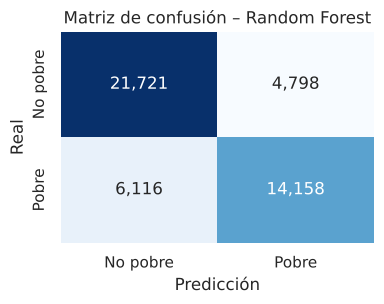

In [28]:
p = dict(mejores["Random Forest"]); p["max_depth"] = None if p["max_depth"] == 0 else p["max_depth"]
t0 = time.time()
rf = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=SEMILLA, **p).fit(Xs_tr, y_tr)
registrar_prob("Random Forest", rf.predict_proba(Xs_val)[:, 1], rf.predict_proba(Xs_test)[:, 1], time.time() - t0)

### 11.3 Regresión logística


===== Regresión logística =====
              precision    recall  f1-score   support

    No pobre     0.7676    0.8209    0.7934     26519
       Pobre     0.7423    0.6749    0.7070     20274

    accuracy                         0.7576     46793
   macro avg     0.7550    0.7479    0.7502     46793
weighted avg     0.7566    0.7576    0.7559     46793

ROC-AUC: 0.8342 | MCC: 0.5028


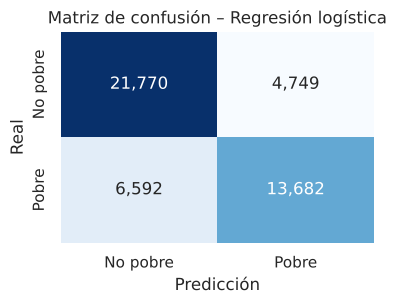

In [29]:
t0 = time.time()
lr_mod = LogisticRegression(max_iter=3000, **mejores["Regresión logística"]).fit(Xs_tr, y_tr)
registrar_prob("Regresión logística", lr_mod.predict_proba(Xs_val)[:, 1], lr_mod.predict_proba(Xs_test)[:, 1], time.time() - t0)

### 11.4 Perceptrón multicapa (MLP)


===== Perceptrón multicapa =====
              precision    recall  f1-score   support

    No pobre     0.7858    0.8245    0.8047     26519
       Pobre     0.7547    0.7061    0.7296     20274

    accuracy                         0.7732     46793
   macro avg     0.7703    0.7653    0.7672     46793
weighted avg     0.7723    0.7732    0.7722     46793

ROC-AUC: 0.8542 | MCC: 0.5356


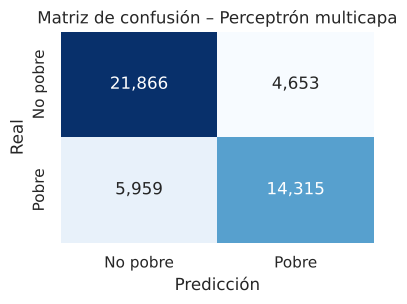

In [30]:
p = dict(mejores["Perceptrón multicapa"]); p["hidden_layer_sizes"] = ARQ_MLP[p.pop("capas")]
t0 = time.time()
mlp = MLPClassifier(early_stopping=True, n_iter_no_change=10, max_iter=200, random_state=SEMILLA, **p).fit(Xs_tr, y_tr)
registrar_prob("Perceptrón multicapa", mlp.predict_proba(Xs_val)[:, 1], mlp.predict_proba(Xs_test)[:, 1], time.time() - t0)

### 11.5 Perceptrón simple (clásico) y perceptrón promediado
El perceptrón no estima probabilidades: se usa su función de decisión para el ROC‑AUC y no participa en el ensamble.


===== Perceptrón =====
              precision    recall  f1-score   support

    No pobre     0.7123    0.8493    0.7748     26519
       Pobre     0.7366    0.5512    0.6306     20274

    accuracy                         0.7202     46793
   macro avg     0.7244    0.7003    0.7027     46793
weighted avg     0.7228    0.7202    0.7123     46793

ROC-AUC: 0.7905 | MCC: 0.4240


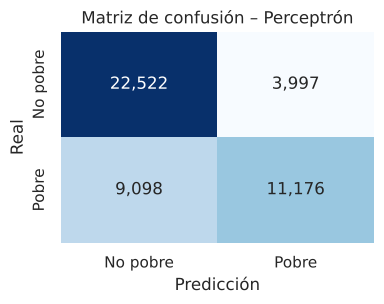


===== Perceptrón promediado =====
              precision    recall  f1-score   support

    No pobre     0.7738    0.8081    0.7906     26519
       Pobre     0.7335    0.6909    0.7116     20274

    accuracy                         0.7573     46793
   macro avg     0.7536    0.7495    0.7511     46793
weighted avg     0.7563    0.7573    0.7563     46793

ROC-AUC: 0.8341 | MCC: 0.5031


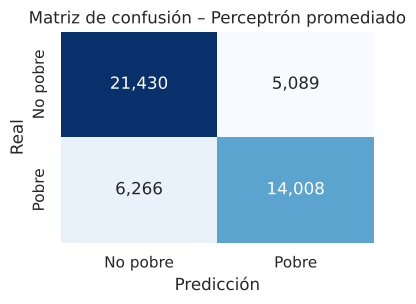

In [31]:
t0 = time.time()
per = Perceptron(max_iter=200, random_state=SEMILLA, **mejores["Perceptrón"]).fit(Xs_tr, y_tr)
registrar("Perceptrón", per.decision_function(Xs_test), per.predict(Xs_test), time.time() - t0)

t0 = time.time()
per_avg = SGDClassifier(loss="perceptron", average=True, max_iter=50, tol=1e-4, random_state=SEMILLA,
                        **mejores["Perceptrón promediado"]).fit(Xs_tr, y_tr)
registrar("Perceptrón promediado", per_avg.decision_function(Xs_test), per_avg.predict(Xs_test), time.time() - t0)

### 11.6 XGBoost

Árboles (mejor iteración + 1): 1243



===== XGBoost =====
              precision    recall  f1-score   support

    No pobre     0.7879    0.8270    0.8070     26519
       Pobre     0.7580    0.7088    0.7326     20274

    accuracy                         0.7758     46793
   macro avg     0.7729    0.7679    0.7698     46793
weighted avg     0.7749    0.7758    0.7747     46793

ROC-AUC: 0.8573 | MCC: 0.5408


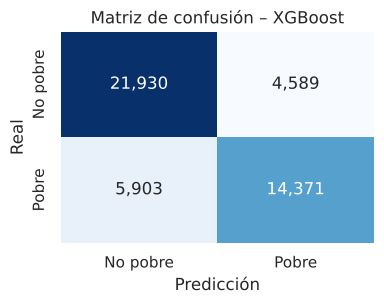

In [32]:
t0 = time.time()
xgb_mod = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="logloss", early_stopping_rounds=50,
                            random_state=SEMILLA, n_jobs=-1, **mejores["XGBoost"])
xgb_mod.fit(Xs_tr, y_tr, eval_set=[(Xs_val, y_val)], verbose=False)
print("Árboles (mejor iteración + 1):", xgb_mod.best_iteration + 1)
registrar_prob("XGBoost", xgb_mod.predict_proba(Xs_val)[:, 1], xgb_mod.predict_proba(Xs_test)[:, 1], time.time() - t0)

### 11.7 Gradient Boosting

Iteraciones: 564



===== Gradient Boosting =====
              precision    recall  f1-score   support

    No pobre     0.7883    0.8277    0.8075     26519
       Pobre     0.7589    0.7092    0.7332     20274

    accuracy                         0.7764     46793
   macro avg     0.7736    0.7684    0.7703     46793
weighted avg     0.7755    0.7764    0.7753     46793

ROC-AUC: 0.8569 | MCC: 0.5420


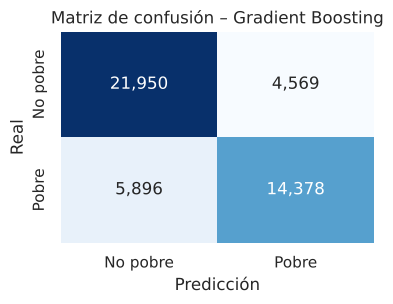

In [33]:
p = dict(mejores["Gradient Boosting"]); p["max_depth"] = None if p["max_depth"] == 0 else p["max_depth"]
t0 = time.time()
gb = HistGradientBoostingClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
                                    random_state=SEMILLA, **p).fit(Xs_tr, y_tr)
print("Iteraciones:", gb.n_iter_)
registrar_prob("Gradient Boosting", gb.predict_proba(Xs_val)[:, 1], gb.predict_proba(Xs_test)[:, 1], time.time() - t0)

### 11.8 Ensamble ponderado optimizado
Se combinan las probabilidades de los seis modelos probabilísticos mediante un promedio ponderado. Los pesos se optimizan con TPE (300 pruebas) **en el conjunto de validación**; los modelos con peso pequeño quedan prácticamente excluidos.

,Peso
FCNN (128-64-32-16-1),0.299
Gradient Boosting,0.266
Random Forest,0.205
XGBoost,0.158
Perceptrón multicapa,0.061
Regresión logística,0.010


Exactitud del ensamble en validación: 0.7847

===== Ensamble ponderado =====
              precision    recall  f1-score   support

    No pobre     0.7867    0.8303    0.8079     26519
       Pobre     0.7607    0.7055    0.7321     20274

    accuracy                         0.7762     46793
   macro avg     0.7737    0.7679    0.7700     46793
weighted avg     0.7754    0.7762    0.7751     46793

ROC-AUC: 0.8568 | MCC: 0.5416


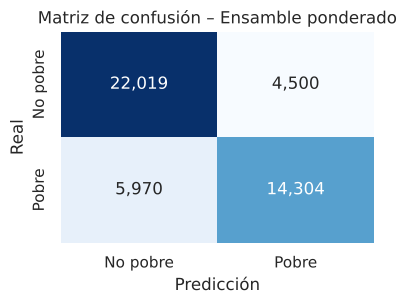

In [34]:
NOMBRES_ENS = list(proba_val)
PV = np.column_stack([proba_val[n] for n in NOMBRES_ENS]); PT = np.column_stack([proba_test[n] for n in NOMBRES_ENS])

def obj_ens(trial):
    w = np.array([trial.suggest_float(f"w_{i}", 0.0, 1.0) for i in range(len(NOMBRES_ENS))])
    if w.sum() == 0: return 0.0
    return accuracy_score(y_val, (PV @ (w / w.sum())) >= 0.5)

est_ens = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEMILLA, multivariate=True))
est_ens.optimize(obj_ens, n_trials=300)
w = np.array([est_ens.best_params[f"w_{i}"] for i in range(len(NOMBRES_ENS))]); w = w / w.sum()
pesos = pd.Series(w, index=NOMBRES_ENS).sort_values(ascending=False)
display(pesos.round(3).to_frame("Peso"))
print(f"Exactitud del ensamble en validación: {est_ens.best_value:.4f}")
t0 = time.time()
registrar_prob("Ensamble ponderado", PV @ w, PT @ w, time.time() - t0)

### 11.9 Calibración del umbral de decisión
Para cada modelo probabilístico se elige, **en validación**, el umbral que maximiza la exactitud (búsqueda en una malla de 0.30 a 0.70) y se aplica al conjunto de prueba. La tabla compara la exactitud con umbral 0.5 y con el umbral calibrado.

In [35]:
malla = np.round(np.arange(0.30, 0.701, 0.005), 3)
filas = []
for n in proba_val:
    accs = [accuracy_score(y_val, proba_val[n] >= u) for u in malla]
    u_opt = malla[int(np.argmax(accs))]
    pred_u = (proba_test[n] >= u_opt).astype(int)
    filas.append({"Modelo": n, "Umbral óptimo (validación)": u_opt,
                  "Accuracy prueba (u=0.5)": accuracy_score(y_test, proba_test[n] >= 0.5),
                  "Accuracy prueba (u óptimo)": accuracy_score(y_test, pred_u),
                  "F1 prueba (u óptimo)": f1_score(y_test, pred_u, average="weighted"),
                  "MCC prueba (u óptimo)": matthews_corrcoef(y_test, pred_u)})
tabla_umbral = pd.DataFrame(filas).sort_values("Accuracy prueba (u óptimo)", ascending=False)
display(tabla_umbral.round(4))
tabla_umbral.to_csv(os.path.join(CARPETA_SALIDA, "umbral_calibrado.csv"), index=False)

,Modelo,Umbral óptimo (validación),Accuracy prueba (u=0.5),Accuracy prueba (u óptimo),F1 prueba (u óptimo),MCC prueba (u óptimo)
5,Gradient Boosting,0.505,0.7764,0.7765,0.7752,0.5420
6,Ensamble ponderado,0.500,0.7762,0.7762,0.7751,0.5416
4,XGBoost,0.520,0.7758,0.7756,0.7737,0.5397
3,Perceptrón multicapa,0.505,0.7732,0.7733,0.7720,0.5354
0,FCNN (128-64-32-16-1),0.500,0.7719,0.7719,0.7705,0.5324
1,Random Forest,0.505,0.7668,0.7670,0.7657,0.5224
2,Regresión logística,0.485,0.7576,0.7573,0.7563,0.5030


### 11.10 Comparación: búsqueda aleatoria (versión 1) frente a optimización bayesiana (versión 2)
Exactitud en el mismo conjunto de prueba. Los valores de la versión 1 provienen de la ejecución anterior del flujo con `RandomizedSearchCV` (misma partición y semilla).

In [36]:
v1 = {"XGBoost": 0.7779, "Gradient Boosting": 0.7772, "Perceptrón multicapa": 0.7753, "FCNN (128-64-32-16-1)": 0.7750,
      "Random Forest": 0.7664, "Regresión logística": 0.7576, "Perceptrón promediado": 0.7545, "Perceptrón": 0.5804}
v2 = pd.DataFrame(resultados).set_index("Modelo")["Accuracy"]
comp = pd.DataFrame({"V1: búsqueda aleatoria": pd.Series(v1), "V2: Optuna (TPE)": v2})
comp["Diferencia (p. p.)"] = 100 * (comp.iloc[:, 1] - comp.iloc[:, 0])
display(comp.sort_values("V2: Optuna (TPE)", ascending=False).round(4))
comp.to_csv(os.path.join(CARPETA_SALIDA, "comparacion_v1_v2.csv"))

,V1: búsqueda aleatoria,V2: Optuna (TPE),Diferencia (p. p.)
Gradient Boosting,0.7772,0.7764,-0.0845
Ensamble ponderado,NaN,0.7762,NaN
XGBoost,0.7779,0.7758,-0.2122
Perceptrón multicapa,0.7753,0.7732,-0.2086
FCNN (128-64-32-16-1),0.7750,0.7719,-0.3132
Random Forest,0.7664,0.7668,0.0360
Regresión logística,0.7576,0.7576,0.0035
Perceptrón promediado,0.7545,0.7573,0.2835
Perceptrón,0.5804,0.7202,13.9750


## 12. Comparación de modelos y pruebas estadísticas
* **Tabla de métricas** (precisión, recall y F1 ponderados, como en el flujo original, más métricas de la clase *pobre*, ROC‑AUC y MCC).
* **Intervalos de confianza al 95 %** de la exactitud mediante *bootstrap* (1 000 remuestreos del conjunto de prueba).
* **Prueba de McNemar** (con corrección de continuidad) entre el mejor modelo y cada uno de los demás.

In [37]:
tabla = pd.DataFrame(resultados).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(tabla.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Precision (pobre),Recall (pobre),F1 (pobre),ROC-AUC,MCC,Tiempo (s)
0,Gradient Boosting,0.7764,0.7755,0.7764,0.7753,0.7589,0.7092,0.7332,0.8569,0.5420,32.2730
1,Ensamble ponderado,0.7762,0.7754,0.7762,0.7751,0.7607,0.7055,0.7321,0.8568,0.5416,0.0006
2,XGBoost,0.7758,0.7749,0.7758,0.7747,0.7580,0.7088,0.7326,0.8573,0.5408,34.1600
3,Perceptrón multicapa,0.7732,0.7723,0.7732,0.7722,0.7547,0.7061,0.7296,0.8542,0.5356,46.6609
4,FCNN (128-64-32-16-1),0.7719,0.7710,0.7719,0.7705,0.7579,0.6957,0.7255,0.8531,0.5324,52.0302
5,Random Forest,0.7668,0.7658,0.7668,0.7657,0.7469,0.6983,0.7218,0.8432,0.5223,158.5471
6,Regresión logística,0.7576,0.7566,0.7576,0.7559,0.7423,0.6749,0.7070,0.8342,0.5028,0.8638
7,Perceptrón promediado,0.7573,0.7563,0.7573,0.7563,0.7335,0.6909,0.7116,0.8341,0.5031,3.9909
8,Perceptrón,0.7202,0.7228,0.7202,0.7123,0.7366,0.5512,0.6306,0.7905,0.4240,0.5674


In [38]:
def ic_bootstrap(y_true, pred, B=1000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    n = len(y_true); acier = (y_true == pred).astype(np.float32); acc = np.empty(B)
    for b in range(B):
        acc[b] = acier[rng.integers(0, n, n)].mean()
    return np.percentile(acc, [2.5, 97.5])

def mcnemar(y_true, p1, p2):
    b = np.sum((p1 == y_true) & (p2 != y_true)); c = np.sum((p1 != y_true) & (p2 == y_true))
    est = (abs(b - c) - 1) ** 2 / (b + c) if (b + c) > 0 else 0.0
    return est, 1 - chi2.cdf(est, df=1)

mejor = tabla.loc[0, "Modelo"]
filas = []
for m in tabla.Modelo:
    lo, hi = ic_bootstrap(y_test, predicciones[m]["pred"])
    est, p = (np.nan, np.nan) if m == mejor else mcnemar(y_test, predicciones[mejor]["pred"], predicciones[m]["pred"])
    filas.append({"Modelo": m, "IC95% inf": lo, "IC95% sup": hi, f"McNemar χ² vs {mejor}": est, "p-valor": p})
tabla_estad = pd.DataFrame(filas)
display(tabla_estad.round(4))

,Modelo,IC95% inf,IC95% sup,McNemar χ² vs Gradient Boosting,p-valor
0,Gradient Boosting,0.7724,0.7803,NaN,NaN
1,Ensamble ponderado,0.7725,0.7802,0.0106,0.9178
2,XGBoost,0.7720,0.7799,0.4254,0.5142
3,Perceptrón multicapa,0.7695,0.7770,8.8558,0.0029
4,FCNN (128-64-32-16-1),0.7680,0.7757,16.8133,0.0000
5,Random Forest,0.7630,0.7705,51.5551,0.0000
6,Regresión logística,0.7536,0.7614,159.8382,0.0000
7,Perceptrón promediado,0.7535,0.7612,166.9457,0.0000
8,Perceptrón,0.7161,0.7243,795.5388,0.0000


## 13. Visualizaciones

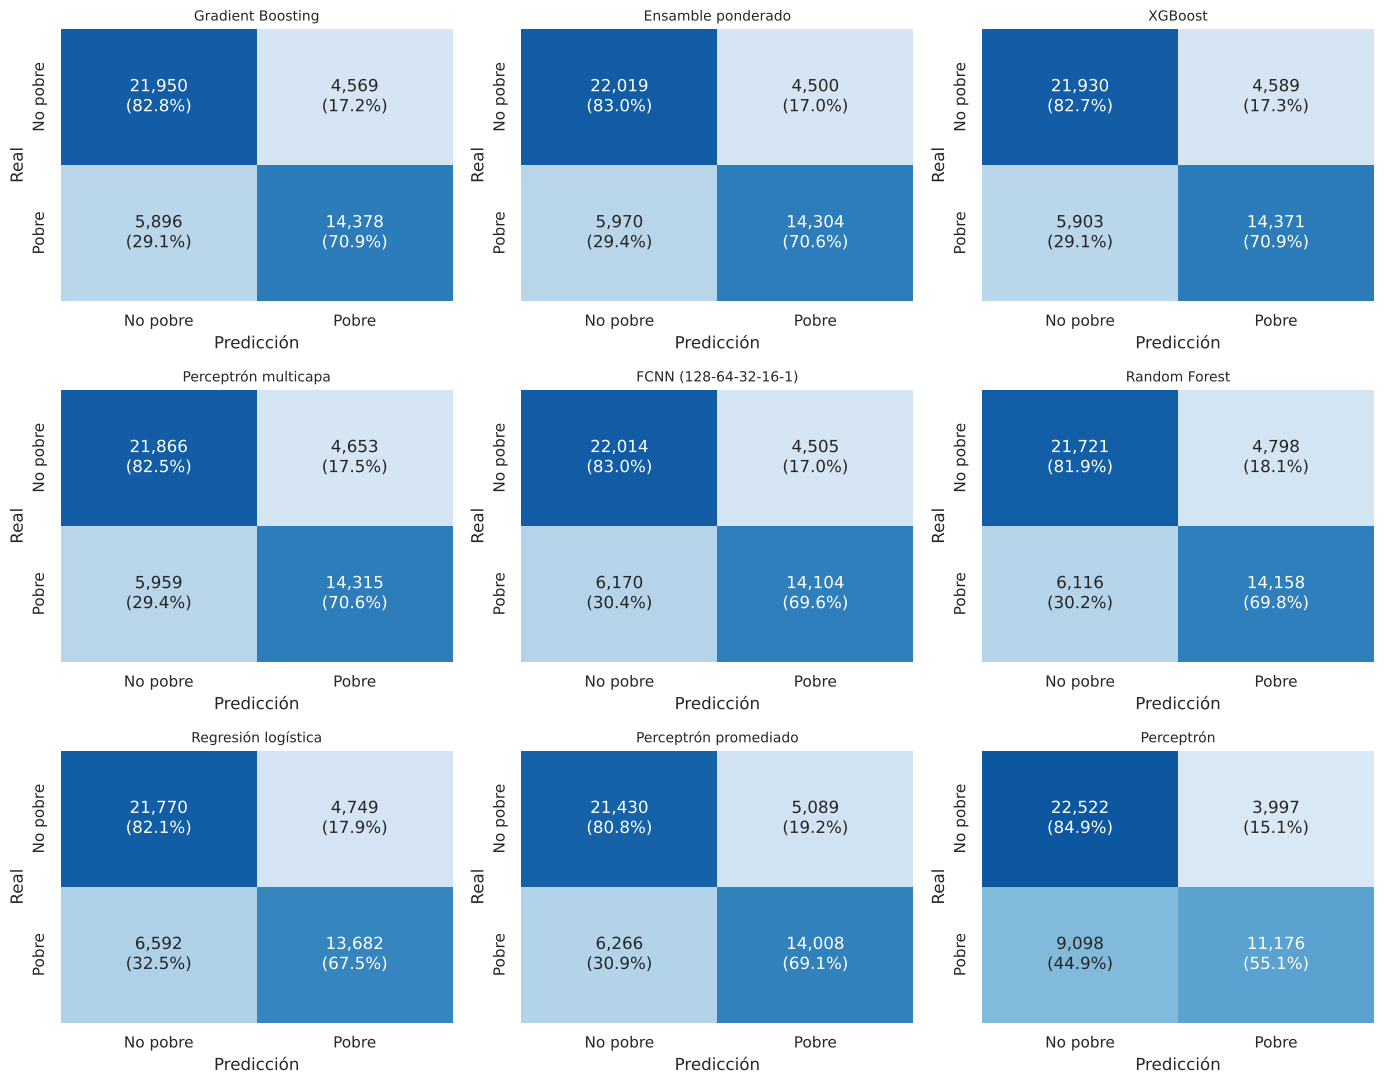

In [39]:
# 13.1 Matrices de confusión normalizadas (por fila) de los siete modelos
fig, axes = plt.subplots(3, 3, figsize=(14, 11))  # 9 modelos
for a_, m in zip(axes.ravel(), tabla.Modelo):
    cm = confusion_matrix(y_test, predicciones[m]["pred"])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    etiquetas = np.array([[f"{cm[i,j]:,}\n({cmn[i,j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a_,
                xticklabels=["No pobre", "Pobre"], yticklabels=["No pobre", "Pobre"])
    a_.set_title(m, fontsize=10); a_.set_xlabel("Predicción"); a_.set_ylabel("Real")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_matrices_confusion.png"), dpi=300); plt.show()

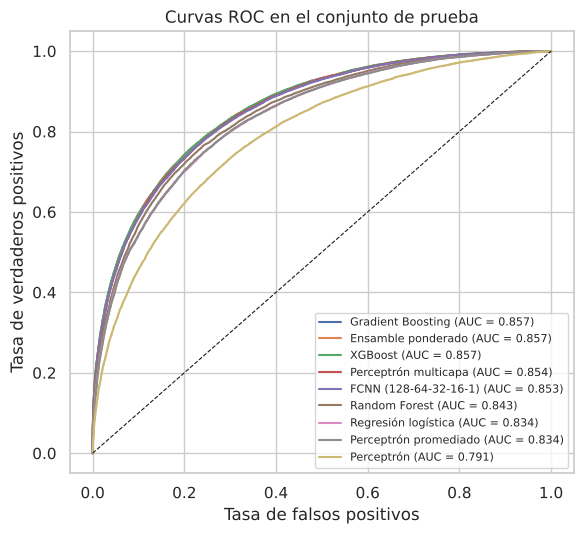

In [40]:
# 13.2 Curvas ROC
plt.figure(figsize=(6, 5.5))
for m in tabla.Modelo:
    fpr, tpr, _ = roc_curve(y_test, predicciones[m]["puntaje"])
    plt.plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_test, predicciones[m]['puntaje']):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Tasa de verdaderos positivos")
plt.legend(fontsize=8, loc="lower right"); plt.title("Curvas ROC en el conjunto de prueba")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_roc.png"), dpi=300); plt.show()

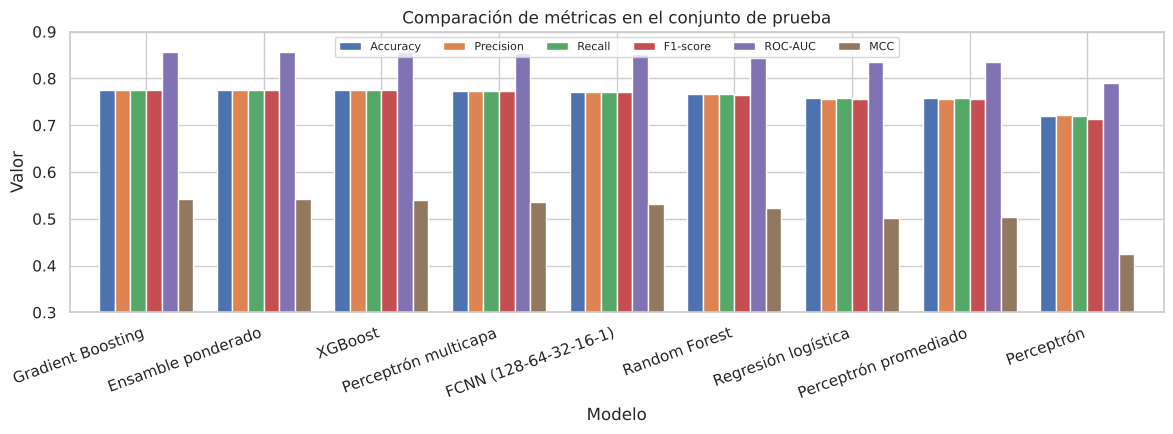

In [41]:
# 13.3 Comparación de métricas
met = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "MCC"]
tabla.set_index("Modelo")[met].plot(kind="bar", figsize=(12, 4.5), width=0.8)
plt.ylim(0.3, 0.9); plt.ylabel("Valor"); plt.xticks(rotation=20, ha="right")
plt.legend(ncol=6, fontsize=8, loc="upper center"); plt.title("Comparación de métricas en el conjunto de prueba")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_metricas.png"), dpi=300); plt.show()

## 14. Estudio de ablación: efecto de cada mejora
Se compara, **sobre la misma partición**, el efecto acumulado de (a) imputar en lugar de eliminar filas, (b) escalar y (c) añadir la ingeniería de características. Se usan la regresión logística, los perceptrones y XGBoost con hiperparámetros fijos (por defecto) para aislar el efecto del preprocesamiento.

También se muestran los resultados registrados en el **notebook original** (partición aleatoria no estratificada, sin escalado y con hiperparámetros por defecto) como referencia.

In [42]:
COLS_FE = ["bano_comp_nulo", "tasa_dependencia", "trab_por_integ", "hacinamiento", "integ_por_bano",
           "inseg_alim_suma", "indice_bienes", "sin_trabajador"]

def prep_config(escalar, usar_fe):
    num = [c for c in NUM if usar_fe or c not in COLS_FE]
    binv = [c for c in BIN if usar_fe or c not in COLS_FE]
    pasos = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(pasos), num),
                              ("bin", SimpleImputer(strategy="most_frequent"), binv),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

configs = {"A. Imputación, sin escalado, sin FE": (False, False),
           "B. + Escalado": (True, False),
           "C. + Escalado + FE (flujo propuesto)": (True, True)}
modelos_abl = {
    "Regresión logística": lambda: LogisticRegression(max_iter=3000),
    "Perceptrón": lambda: Perceptron(random_state=SEMILLA),
    "Perceptrón promediado": lambda: SGDClassifier(loss="perceptron", average=True, random_state=SEMILLA),
    "XGBoost (por defecto)": lambda: xgb.XGBClassifier(tree_method="hist", random_state=SEMILLA, n_jobs=-1)}
filas = []
for cfg, (esc, fe_) in configs.items():
    p = prep_config(esc, fe_).fit(X_train)
    A, B = p.transform(X_train), p.transform(X_test)
    for nm, f in modelos_abl.items():
        pr = f().fit(A, y_train).predict(B)
        filas.append({"Configuración": cfg, "Modelo": nm, "Accuracy": accuracy_score(y_test, pr),
                      "F1-score": f1_score(y_test, pr, average="weighted")})
ablacion = pd.DataFrame(filas).pivot(index="Configuración", columns="Modelo", values="Accuracy")
display(ablacion.round(4))

Modelo,Perceptrón,Perceptrón promediado,Regresión logística,XGBoost (por defecto)
Configuración,,,,
"A. Imputación, sin escalado, sin FE",0.7516,0.7478,0.7549,0.7739
B. + Escalado,0.6785,0.7558,0.7549,0.7739
C. + Escalado + FE (flujo propuesto),0.6745,0.7564,0.7576,0.7744


In [43]:
# Resultados reportados por el notebook original (referencia; partición distinta, n_prueba = 45 626)
original = pd.DataFrame({
    "Modelo": ["Random Forest", "Red neuronal full connected (128-64-32)", "Perceptrón multicapa (100)",
               "Regresión logística", "Perceptrón simple"],
    "Accuracy": [0.7661, 0.7653, 0.7629, 0.7507, 0.6525],
    "F1-score": [0.7644, 0.7651, 0.7572, 0.7492, 0.6431]})
display(original)

,Modelo,Accuracy,F1-score
0,Random Forest,0.7661,0.7644
1,Red neuronal full connected (128-64-32),0.7653,0.7651
2,Perceptrón multicapa (100),0.7629,0.7572
3,Regresión logística,0.7507,0.7492
4,Perceptrón simple,0.6525,0.6431


## 15. Interpretabilidad: importancia por permutación
Se mide la disminución de la exactitud del mejor modelo de árboles al permutar aleatoriamente cada variable **original** (las variables derivadas se recalculan después de permutar). Se usa una submuestra de 15 000 hogares del conjunto de prueba y 5 repeticiones.

Modelo analizado: Gradient Boosting


,media,desv
tot_integ,0.1040,0.0017
prog_soc_porcent,0.0685,0.0016
tot_trab,0.0415,0.0009
rur_urb,0.0282,0.0008
entidad,0.0201,0.0018
escolaridad_educacion_jh,0.0159,0.0010
anio,0.0095,0.0011
tot_integ_0_17,0.0066,0.0014
edad_jefe,0.0064,0.0014
auto_camioneta_van,0.0063,0.0013


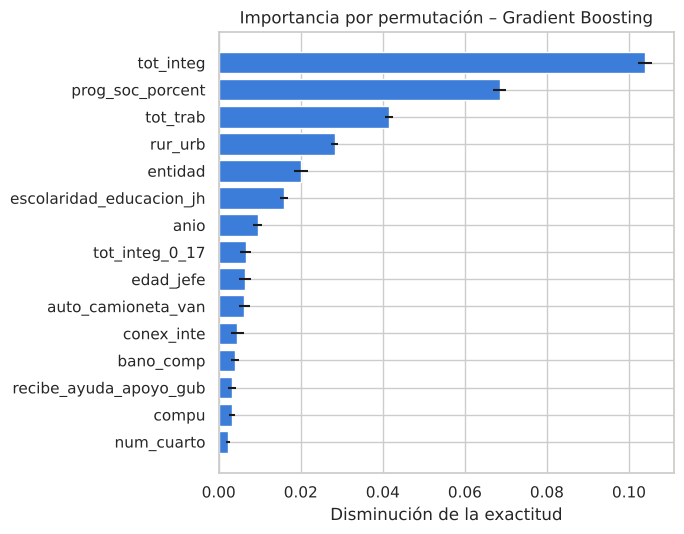

In [44]:
def importancia_permutacion(predecir, Xr, yr, n_rep=5, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    base = accuracy_score(yr, predecir(ingenieria_caracteristicas(Xr)))
    imp = {}
    for c in Xr.columns:
        caidas = []
        for _ in range(n_rep):
            Xp = Xr.copy(); Xp[c] = rng.permutation(Xp[c].values)
            caidas.append(base - accuracy_score(yr, predecir(ingenieria_caracteristicas(Xp))))
        imp[c] = (np.mean(caidas), np.std(caidas))
    return pd.DataFrame(imp, index=["media", "desv"]).T.sort_values("media", ascending=False)

modelos_arbol = {"XGBoost": lambda Z: xgb_mod.predict(pre_tr.transform(Z)),
                 "Gradient Boosting": lambda Z: gb.predict(pre_tr.transform(Z)),
                 "Random Forest": lambda Z: rf.predict(pre_tr.transform(Z))}
mejor_arbol = tabla[tabla.Modelo.isin(modelos_arbol)].iloc[0].Modelo
print("Modelo analizado:", mejor_arbol)

idx_imp, _ = train_test_split(np.arange(len(y_test)), train_size=15_000, stratify=y_test, random_state=SEMILLA)
Xr_test = X_test.iloc[idx_imp][X_raw.columns]
imp = importancia_permutacion(modelos_arbol[mejor_arbol], Xr_test, y_test[idx_imp])
display(imp.head(15).round(4))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(7, 5.5))
plt.barh(top.index, top["media"], xerr=top["desv"], color="#3B7DD8")
plt.xlabel("Disminución de la exactitud"); plt.title(f"Importancia por permutación – {mejor_arbol}")
plt.tight_layout(); plt.savefig(os.path.join(CARPETA_SALIDA, "fig_importancia.png"), dpi=300); plt.show()

### 15.1 Análisis de sensibilidad: variable `prog_soc_porcent`
`prog_soc_porcent` es la proporción del ingreso del hogar que proviene de programas sociales; al estar expresada respecto del ingreso, contiene información **indirecta** del ingreso. Para cuantificar su efecto se reentrena XGBoost (mismos hiperparámetros y *early stopping*) excluyéndola.

In [45]:
sin_ps = [c for c in X.columns if c != "prog_soc_porcent"]
NUM_bak = NUM.copy()
NUM = [c for c in NUM if c != "prog_soc_porcent"]
pre_s = crear_preprocesador().fit(X_tr[sin_ps])
NUM = NUM_bak
xgb_s = xgb.XGBClassifier(n_estimators=3000, tree_method="hist", eval_metric="logloss", early_stopping_rounds=50,
                          random_state=SEMILLA, n_jobs=-1, **mejores["XGBoost"])
xgb_s.fit(pre_s.transform(X_tr[sin_ps]), y_tr, eval_set=[(pre_s.transform(X_val[sin_ps]), y_val)], verbose=False)
p_s = xgb_s.predict_proba(pre_s.transform(X_test[sin_ps]))[:, 1]
sens = pd.DataFrame({"Variante": ["XGBoost (todas las variables)", "XGBoost sin prog_soc_porcent"],
                     "Accuracy": [accuracy_score(y_test, predicciones["XGBoost"]["pred"]), accuracy_score(y_test, p_s >= 0.5)],
                     "ROC-AUC": [roc_auc_score(y_test, predicciones["XGBoost"]["puntaje"]), roc_auc_score(y_test, p_s)],
                     "MCC": [matthews_corrcoef(y_test, predicciones["XGBoost"]["pred"]), matthews_corrcoef(y_test, p_s >= 0.5)]})
display(sens.round(4))
sens.to_csv(os.path.join(CARPETA_SALIDA, "sensibilidad_prog_soc.csv"), index=False)

,Variante,Accuracy,ROC-AUC,MCC
0,XGBoost (todas las variables),0.7758,0.8573,0.5408
1,XGBoost sin prog_soc_porcent,0.7553,0.8358,0.4989


## 16. Exportación de resultados

In [46]:
tabla.to_csv(os.path.join(CARPETA_SALIDA, "metricas_modelos.csv"), index=False)
tabla_estad.to_csv(os.path.join(CARPETA_SALIDA, "ic_y_mcnemar.csv"), index=False)
ablacion.to_csv(os.path.join(CARPETA_SALIDA, "ablacion.csv"))
imp.to_csv(os.path.join(CARPETA_SALIDA, "importancia_permutacion.csv"))
print("Archivos guardados en:", os.path.abspath(CARPETA_SALIDA))
print(os.listdir(CARPETA_SALIDA))

Archivos guardados en: /home/claude/resultados_pobreza_v2
['ablacion.csv', 'ic_y_mcnemar.csv', 'metricas_modelos.csv', 'mejores_hiperparametros_optuna.json', 'umbral_calibrado.csv', 'sensibilidad_prog_soc.csv', 'importancia_permutacion.csv', 'fig_importancia.png', 'comparacion_v1_v2.csv', 'fig_roc.png', 'optuna_pobreza.db', 'fig_metricas.png', 'fig_curvas_fcnn.png', 'fig_historial_optuna.png', 'fig_matrices_confusion.png']


## 17. Conclusiones

**Resultados en el conjunto de prueba (46 793 hogares)**

| Modelo | Accuracy V2 (Optuna) | ROC-AUC | MCC | Accuracy V1 (búsqueda aleatoria) |
|---|---|---|---|---|
| Gradient Boosting | 0.7764 | 0.8569 | 0.5420 | 0.7772 |
| Ensamble ponderado | 0.7762 | 0.8568 | 0.5416 | — |
| XGBoost | 0.7758 | 0.8573 | 0.5408 | 0.7779 |
| Perceptrón multicapa | 0.7732 | 0.8542 | 0.5356 | 0.7753 |
| FCNN (128-64-32-16-1) | 0.7719 | 0.8531 | 0.5324 | 0.7750 |
| Random Forest | 0.7668 | 0.8432 | 0.5223 | 0.7664 |
| Regresión logística | 0.7576 | 0.8342 | 0.5028 | 0.7576 |
| Perceptrón promediado | 0.7573 | 0.8341 | 0.5031 | 0.7545 |
| Perceptrón | 0.7202 | 0.7905 | 0.4240 | 0.5804 |

1. **La optimización bayesiana no mejoró a los mejores modelos.** Gradient Boosting (0.7764), el ensamble ponderado (0.7762) y XGBoost (0.7758) son estadísticamente equivalentes entre sí (McNemar, p > 0.5) y quedan prácticamente iguales a la versión 1 (XGBoost 0.7779); las diferencias entre versiones (−0.31 a +0.04 p. p.) están dentro de los intervalos de confianza (±0.4 p. p.).
2. **Donde sí hubo mejora:** el perceptrón clásico pasó de 0.5804 a 0.7202 (+13.98 p. p.), porque TPE encontró una configuración sin *early stopping* y con pesos balanceados que evita su inestabilidad; el perceptrón promediado mejoró +0.28 p. p.
3. **Brecha validación–prueba:** todos los modelos rinden 0.4–1.1 p. p. más en validación que en prueba, incluida la regresión logística (casi sin hiperparámetros). Esto indica que (a) la partición de validación es algo más favorable y (b) elegir la mejor de muchas configuraciones introduce un sesgo optimista. Por eso **solo deben reportarse las cifras de prueba**.
4. **Ensamble y umbral:** el ensamble (pesos: FCNN 0.30, Gradient Boosting 0.27, Random Forest 0.21, XGBoost 0.16) no supera al mejor modelo individual; el umbral calibrado (0.485–0.520) cambia la exactitud menos de 0.03 p. p., porque las clases están casi balanceadas y las probabilidades están bien calibradas.
5. **Conclusión metodológica:** con las variables disponibles el desempeño se satura alrededor de **0.776–0.778** de exactitud y 0.857 de ROC‑AUC. El límite lo impone la información de los predictores, no el método de optimización. Sin `prog_soc_porcent` (información indirecta del ingreso) la exactitud de XGBoost baja a 0.7553.

**Para mejorar realmente las métricas** haría falta información nueva (otras variables de la ENIGH: características de la vivienda, ocupación y tipo de empleo, gasto del hogar, etc.), no más ajuste de hiperparámetros.
